Hagamos unos plots iniciales

In [9]:
"""
Genera la visualización definitiva 2017:
- Panel A: Mapa de pluma AERMOD sobre contornos reales de CDMX, EdoMex y municipios ZMVM.
- Panel B: % Directo de Alumnos en Nivel I (Insuficiente) en Matemáticas y Lenguaje por Quintil de Exposición.
"""
import os, urllib.request, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape


In [10]:

BASE = "/Users/gabrielevangelista/thesis-cdmx-air"
PLT_FILE = f"{BASE}/03-analysis/run_aermod/plot_annual_all_2017.plt"
SOURCES_CSV = f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv"
OUT_FIG = f"{BASE}/03-analysis/run_aermod/figura_definitiva_asesora_2017.png"
GEOJSON_LOCAL = f"{BASE}/02-data/processed/aermap_out/zmvm_municipios.geojson"

def get_geopandas_boundaries():
    # Descargar un GeoJSON limpio de municipios de México si no existe
    if not os.path.exists(GEOJSON_LOCAL):
        os.makedirs(os.path.dirname(GEOJSON_LOCAL), exist_ok=True)
        url = "https://raw.githubusercontent.com/angelnmara/geojson/master/Municipios_Mexico.json"
        try:
            print("Descargando contornos municipales oficiales...")
            urllib.request.urlretrieve(url, GEOJSON_LOCAL)
        except Exception:
            pass

    if os.path.exists(GEOJSON_LOCAL):
        gdf = gpd.read_file(GEOJSON_LOCAL)
        # Filtrar ZMVM / Centro (CDMX cve_ent == '09', EdoMex cve_ent == '15', Hidalgo '13' o por nombres de municipios metropolitanos)
        if "cve_ent" in gdf.columns:
            gdf_zmvm = gdf[gdf["cve_ent"].isin(["09", "15"])].copy()
        elif "CVE_ENT" in gdf.columns:
            gdf_zmvm = gdf[gdf["CVE_ENT"].isin(["09", "15"])].copy()
        else:
            gdf_zmvm = gdf.copy()
        return gdf_zmvm.to_crs("EPSG:32614")
    return None

def parse_aermod_plt(filepath):
    records = []
    with open(filepath, "r") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("*"):
                continue
            p = s.split()
            if len(p) >= 3:
                try:
                    records.append({"X_UTM": round(float(p[0]), 2), "Y_UTM": round(float(p[1]), 2), "PM25_CONC": float(p[2])})
                except ValueError:
                    continue
    return pd.DataFrame(records)

In [11]:
df_plt = parse_aermod_plt(PLT_FILE)
df_src = pd.read_csv(SOURCES_CSV)
df_src_active = df_src[df_src["Q_GS_2017"] > 0].copy()

# Cargar panel PLANEA enlazado que generamos antes
planea_path = f"{BASE}/02-data/processed/aermap_out/planea_enlazado_receptores_2015_2019.csv"
df_planea = pd.read_csv(planea_path)
df_2017 = df_planea[df_planea["anio"] == 2017].copy()
df_2017["X_UTM"] = df_2017["X_UTM"].round(2)
df_2017["Y_UTM"] = df_2017["Y_UTM"].round(2)

# Filtrar ZMVM pública (X_UTM >= 460 km, excluyendo Toluca y privadas)
df_m = df_2017.merge(df_plt, on=["X_UTM", "Y_UTM"], how="inner")
df_zmvm = df_m[
    (df_m["X_UTM"] >= 460000) &
    (~df_m["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False))
].dropna(subset=["PM25_CONC", "mat_pct_n1", "lyc_pct_n1"]).copy()

df_zmvm["quintil_pm"] = pd.qcut(
    df_zmvm["PM25_CONC"], q=5,
    labels=["Q1\n(Menor exp.)", "Q2", "Q3", "Q4", "Q5\n(Mayor exp.)"]
)

summary = df_zmvm.groupby("quintil_pm", observed=False).agg(
    n_escuelas=("cct", "count"),
    pm_mean=("PM25_CONC", "mean"),
    mat_n1_mean=("mat_pct_n1", "mean"),
    mat_n1_se=("mat_pct_n1", lambda x: x.std() / np.sqrt(len(x))),
    lyc_n1_mean=("lyc_pct_n1", "mean"),
    lyc_n1_se=("lyc_pct_n1", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

print("\n=== RESUMEN POR QUINTIL DE EXPOSICIÓN (ZMVM PÚBLICAS 2017) ===")
print(summary.to_string(index=False))



=== RESUMEN POR QUINTIL DE EXPOSICIÓN (ZMVM PÚBLICAS 2017) ===
      quintil_pm  n_escuelas  pm_mean  mat_n1_mean  mat_n1_se  lyc_n1_mean  lyc_n1_se
Q1\n(Menor exp.)         477 0.018494    60.581342   0.833984    36.092034   0.752441
              Q2         477 0.036159    61.728512   0.728466    33.630398   0.729502
              Q3         477 0.051107    60.120755   0.824614    32.835010   0.747365
              Q4         478 0.071015    59.707531   0.848994    32.096444   0.781420
Q5\n(Mayor exp.)         475 0.138516    60.861684   0.797506    32.738316   0.770612



[OK] Figura definitiva guardada en: /Users/gabrielevangelista/thesis-cdmx-air/03-analysis/run_aermod/figura_definitiva_asesora_2017.png


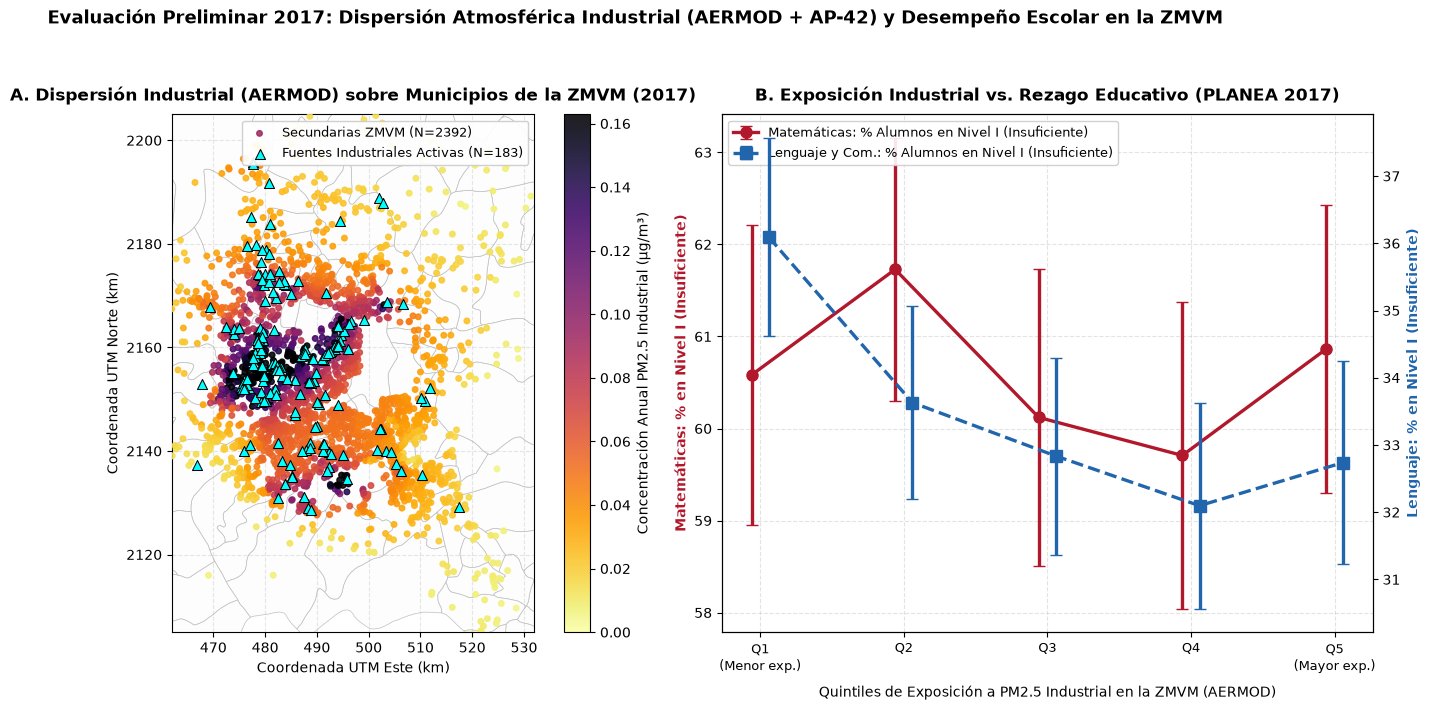

In [12]:

# --- CONFIGURAR FIGURA ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.2), gridspec_kw={"width_ratios": [1.15, 1]})

# Panel A: Mapa con fronteras reales
try:
    gdf_mun = get_geopandas_boundaries()
    if gdf_mun is not None:
        gdf_mun_km = gdf_mun.copy()
        gdf_mun_km["geometry"] = gdf_mun_km["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))
        gdf_mun_km.plot(ax=ax1, facecolor="#fdfdfd", edgecolor="#bfbfbf", linewidth=0.5, zorder=1)
except Exception as e:
    print(f"Nota sobre mapa base: {e}")

df_plt_zmvm = df_plt[df_plt["X_UTM"] >= 460000].copy()
vmax = np.percentile(df_plt_zmvm["PM25_CONC"], 96)
sc = ax1.scatter(
    df_plt_zmvm["X_UTM"] / 1000.0, df_plt_zmvm["Y_UTM"] / 1000.0,
    c=df_plt_zmvm["PM25_CONC"], cmap="inferno_r", s=16, alpha=0.88,
    vmin=0, vmax=vmax, zorder=3, label=f"Secundarias ZMVM (N={len(df_plt_zmvm)})"
)
ax1.scatter(
    df_src_active["X_UTM"] / 1000.0, df_src_active["Y_UTM"] / 1000.0,
    marker="^", c="cyan", edgecolors="black", s=52, linewidths=0.75,
    zorder=4, label=f"Fuentes Industriales Activas (N={len(df_src_active)})"
)

ax1.set_xlim(462, 532)
ax1.set_ylim(2105, 2205)
cbar = plt.colorbar(sc, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label("Concentración Anual PM2.5 Industrial (μg/m³)", fontsize=10)
ax1.set_title("A. Dispersión Industrial (AERMOD) sobre Municipios de la ZMVM (2017)", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Coordenada UTM Este (km)", fontsize=10)
ax1.set_ylabel("Coordenada UTM Norte (km)", fontsize=10)
ax1.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.3, zorder=0)

# Panel B: % Directo en Nivel I (Insuficiente) - Intuitivo y sin dobles negativos
x_idx = np.arange(len(summary))
ax2.errorbar(
    x_idx - 0.06, summary["mat_n1_mean"], yerr=1.96 * summary["mat_n1_se"],
    fmt="-o", color="#b2182b", linewidth=2.4, markersize=8, capsize=4,
    label="Matemáticas: % Alumnos en Nivel I (Insuficiente)"
)
ax2_twin = ax2.twinx()
ax2_twin.errorbar(
    x_idx + 0.06, summary["lyc_n1_mean"], yerr=1.96 * summary["lyc_n1_se"],
    fmt="--s", color="#2166ac", linewidth=2.4, markersize=8, capsize=4,
    label="Lenguaje y Com.: % Alumnos en Nivel I (Insuficiente)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(summary["quintil_pm"], fontsize=9.5)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial en la ZMVM (AERMOD)", fontsize=10, labelpad=8)
ax2.set_ylabel("Matemáticas: % en Nivel I (Insuficiente)", color="#b2182b", fontsize=10, fontweight="bold")
ax2_twin.set_ylabel("Lenguaje: % en Nivel I (Insuficiente)", color="#2166ac", fontsize=10, fontweight="bold")
ax2.set_title("B. Exposición Industrial vs. Rezago Educativo (PLANEA 2017)", fontsize=12, fontweight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.35)

l1, lab1 = ax2.get_legend_handles_labels()
l2, lab2 = ax2_twin.get_legend_handles_labels()
ax2.legend(l1 + l2, lab1 + lab2, loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=9)

plt.suptitle("Evaluación Preliminar 2017: Dispersión Atmosférica Industrial (AERMOD + AP-42) y Desempeño Escolar en la ZMVM", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(OUT_FIG, dpi=300)
print(f"\n[OK] Figura definitiva guardada en: {OUT_FIG}")


## Nueva  versión con varias visualizaciones

In [13]:
import os, glob, urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Preparar el dataframe filtrado para ZMVM Públicas (excluyendo Valle de Toluca X_UTM < 460 km)
df_plt_zmvm = df_plt[df_plt["X_UTM"] >= 460000].copy()
df_zmvm = df_m[
    (df_m["X_UTM"] >= 460000) &
    (~df_m["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False))
].dropna(subset=["PM25_CONC", "mat_pct_n1", "lyc_pct_n1", "mat_parecidas_n1", "lyc_parecidas_n1"]).copy()

# 2. Calcular todas las métricas que usaremos en las Opciones 1, 2, 4 y 3
# Opción 1: Ventaja Neta frente a Escuelas Parecidas (% Nivel I en Parecidas - % Nivel I en la Escuela)
# Un valor más alto significa MEJOR desempeño (menos reprobados que sus pares); si baja hacia Q5, pierden ventaja.
df_zmvm["mat_ventaja_neta"] = df_zmvm["mat_parecidas_n1"] - df_zmvm["mat_pct_n1"]
df_zmvm["lyc_ventaja_neta"] = df_zmvm["lyc_parecidas_n1"] - df_zmvm["lyc_pct_n1"]

# Opción 2: Índice de Desempeño Global PLANEA (Escala 0 a 100 ponderando Niveles I, II, III y IV)
df_zmvm["mat_idx_global"] = ((1*df_zmvm["mat_pct_n1"] + 2*df_zmvm["mat_pct_n2"] + 3*df_zmvm["mat_pct_n3"] + 4*df_zmvm["mat_pct_n4"]) / 3.0) - (100.0 / 3.0)
df_zmvm["mat_idx_parecidas"] = ((1*df_zmvm["mat_parecidas_n1"] + 2*df_zmvm["mat_parecidas_n2"] + 3*df_zmvm["mat_parecidas_n3"] + 4*df_zmvm["mat_parecidas_n4"]) / 3.0) - (100.0 / 3.0)
df_zmvm["mat_idx_neto"] = df_zmvm["mat_idx_global"] - df_zmvm["mat_idx_parecidas"]

df_zmvm["lyc_idx_global"] = ((1*df_zmvm["lyc_pct_n1"] + 2*df_zmvm["lyc_pct_n2"] + 3*df_zmvm["lyc_pct_n3"] + 4*df_zmvm["lyc_pct_n4"]) / 3.0) - (100.0 / 3.0)
df_zmvm["lyc_idx_parecidas"] = ((1*df_zmvm["lyc_parecidas_n1"] + 2*df_zmvm["lyc_parecidas_n2"] + 3*df_zmvm["lyc_parecidas_n3"] + 4*df_zmvm["lyc_parecidas_n4"]) / 3.0) - (100.0 / 3.0)
df_zmvm["lyc_idx_neto"] = df_zmvm["lyc_idx_global"] - df_zmvm["lyc_idx_parecidas"]

# Quintiles y Deciles de Exposición Industrial
df_zmvm["quintil_pm"] = pd.qcut(df_zmvm["PM25_CONC"], q=5, labels=["Q1\n(Menor exp.)", "Q2", "Q3", "Q4", "Q5\n(Mayor exp.)"])
df_zmvm["decil_pm"] = pd.qcut(df_zmvm["PM25_CONC"], q=10, labels=[f"D{i}" for i in range(1, 11)])

# 3. Cargar geometrías y separar claramente el perfil de CDMX (09) vs. Estado de México (15)
GEOJSON_STATES = f"{BASE}/02-data/processed/aermap_out/mexico_estados.geojson"
GEOJSON_MUN = f"{BASE}/02-data/processed/aermap_out/zmvm_municipios_inegi.geojson"

if not os.path.exists(GEOJSON_STATES):
    url_st = "https://raw.githubusercontent.com/angelnmara/geojson/master/mexicoHigh.json"
    urllib.request.urlretrieve(url_st, GEOJSON_STATES)

gdf_st = gpd.read_file(GEOJSON_STATES).to_crs("EPSG:32614")
gdf_st["geometry"] = gdf_st["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))
# Identificar el polígono exacto de Ciudad de México por nombre o centroide (X ~ 485 km, Y ~ 2140 km)
gdf_cdmx = gdf_st[gdf_st.geometry.centroid.x.between(470, 505) & gdf_st.geometry.centroid.y.between(2120, 2165)].copy()

gdf_mun = None
if os.path.exists(GEOJSON_MUN):
    gdf_mun = gpd.read_file(GEOJSON_MUN).to_crs("EPSG:32614")
    gdf_mun["geometry"] = gdf_mun["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))

def dibujar_mapa_zmvm(ax):
    ax.set_facecolor("#f2f4f7")
    # Fondo de Estados y división municipal tenue
    gdf_st.plot(ax=ax, facecolor="#e9ecef", edgecolor="#adb5bd", linewidth=0.8, zorder=1)
    if gdf_mun is not None:
        gdf_mun.plot(ax=ax, facecolor="none", edgecolor="#ced4da", linewidth=0.45, zorder=2)
    # Resaltar silueta de la CDMX con fondo blanco limpio y contorno negro grueso
    if len(gdf_cdmx) > 0:
        gdf_cdmx.plot(ax=ax, facecolor="#ffffff", edgecolor="none", zorder=2)
        gdf_cdmx.boundary.plot(ax=ax, edgecolor="#111111", linewidth=2.2, zorder=5, label="Límite CDMX")

    vmax = np.percentile(df_plt_zmvm["PM25_CONC"], 96)
    sc = ax.scatter(
        df_plt_zmvm["X_UTM"] / 1000.0, df_plt_zmvm["Y_UTM"] / 1000.0,
        c=df_plt_zmvm["PM25_CONC"], cmap="inferno_r", s=15, alpha=0.88,
        vmin=0, vmax=vmax, zorder=3, label=f"Secundarias ZMVM (N={len(df_plt_zmvm)})"
    )
    ax.scatter(
        df_src_active["X_UTM"] / 1000.0, df_src_active["Y_UTM"] / 1000.0,
        marker="^", c="cyan", edgecolors="black", s=48, linewidths=0.75,
        zorder=4, label=f"Fuentes Industriales (N={len(df_src_active)})"
    )
    # Etiquetas geográficas discretas para ubicar al lector
    ax.text(484, 2132, "CDMX", fontsize=10, fontweight="bold", color="#222222", alpha=0.65, zorder=6)
    ax.text(508, 2178, "EDO. DE MÉXICO", fontsize=9.5, fontweight="bold", color="#495057", alpha=0.65, zorder=6)

    ax.set_xlim(458, 535)
    ax.set_ylim(2102, 2210)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cbar.set_label("Concentración Anual PM2.5 Industrial (μg/m³)", fontsize=9.5)
    ax.set_title("A. Pluma Industrial AERMOD y Contorno CDMX / EdoMex (2017)", fontsize=11.5, fontweight="bold", pad=10)
    ax.set_xlabel("Coordenada UTM Este (km)", fontsize=9.5)
    ax.set_ylabel("Coordenada UTM Norte (km)", fontsize=9.5)
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.3, zorder=0)

print("[OK] Función de mapa con contorno CDMX remarcado y métricas listas.")


[OK] Función de mapa con contorno CDMX remarcado y métricas listas.


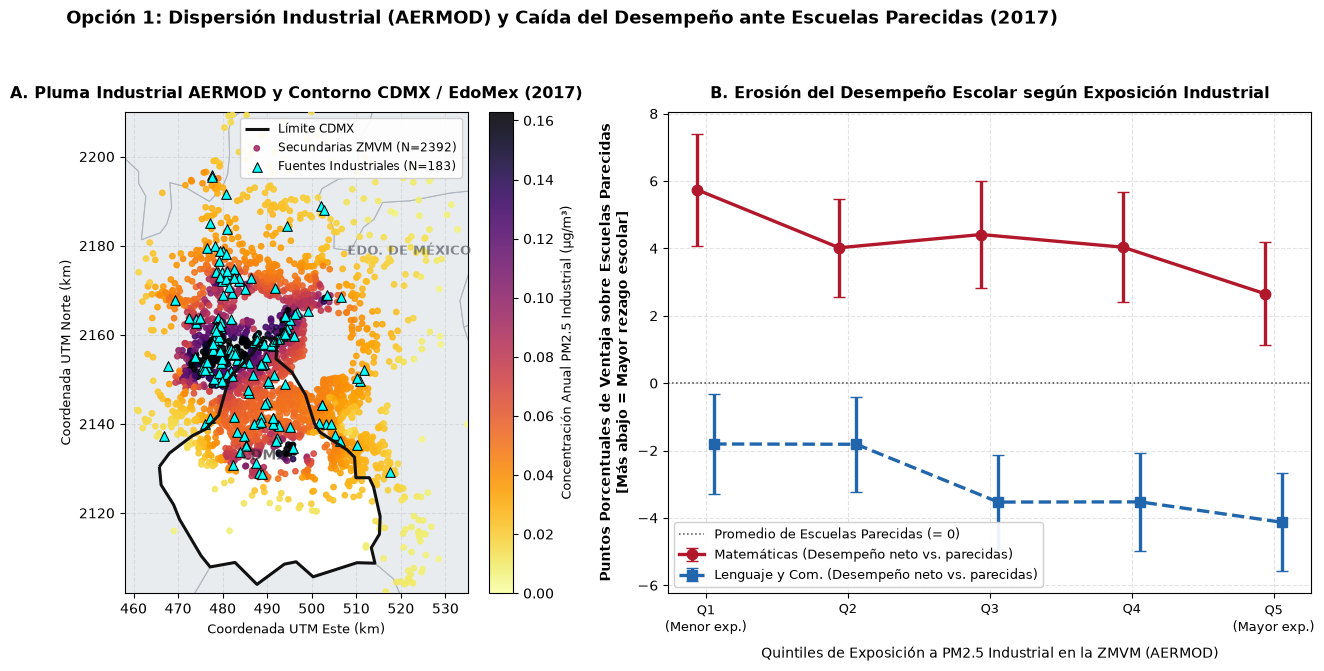

In [14]:
# --- OPCIÓN 1: CAÍDA EN EL DESEMPEÑO NETO FRENTE A ESCUELAS PARECIDAS ---
q_op1 = df_zmvm.groupby("quintil_pm", observed=False).agg(
    mat_mean=("mat_ventaja_neta", "mean"),
    mat_se=("mat_ventaja_neta", lambda x: x.std() / np.sqrt(len(x))),
    lyc_mean=("lyc_ventaja_neta", "mean"),
    lyc_se=("lyc_ventaja_neta", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_idx = np.arange(len(q_op1))
ax2.axhline(0, color="black", linestyle=":", linewidth=1.1, alpha=0.7, label="Promedio de Escuelas Parecidas (= 0)")
ax2.errorbar(
    x_idx - 0.06, q_op1["mat_mean"], yerr=1.96 * q_op1["mat_se"],
    fmt="-o", color="#b2182b", linewidth=2.4, markersize=7.5, capsize=4,
    label="Matemáticas (Desempeño neto vs. parecidas)"
)
ax2.errorbar(
    x_idx + 0.06, q_op1["lyc_mean"], yerr=1.96 * q_op1["lyc_se"],
    fmt="--s", color="#2166ac", linewidth=2.4, markersize=7.5, capsize=4,
    label="Lenguaje y Com. (Desempeño neto vs. parecidas)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_op1["quintil_pm"], fontsize=9.5)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial en la ZMVM (AERMOD)", fontsize=10, labelpad=8)
ax2.set_ylabel("Puntos Porcentuales de Ventaja sobre Escuelas Parecidas\n[Más abajo = Mayor rezago escolar]", fontsize=10, fontweight="bold")
ax2.set_title("B. Erosión del Desempeño Escolar según Exposición Industrial", fontsize=11.5, fontweight="bold", pad=10)
ax2.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=9)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.suptitle("Opción 1: Dispersión Industrial (AERMOD) y Caída del Desempeño ante Escuelas Parecidas (2017)", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_opcion1_ventaja_neta.png", dpi=300)
plt.show()


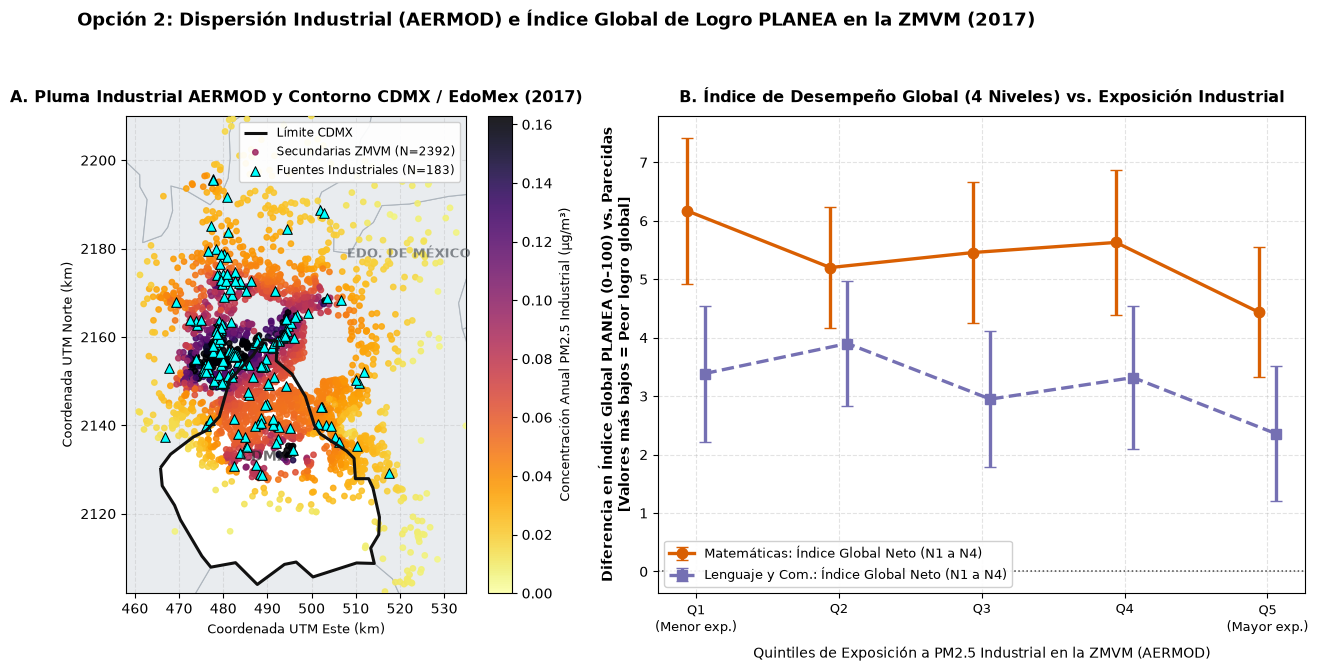

In [15]:
# --- OPCIÓN 2: ÍNDICE DE DESEMPEÑO GLOBAL PONDERADO (NIVELES I A IV) ---
q_op2 = df_zmvm.groupby("quintil_pm", observed=False).agg(
    mat_idx=("mat_idx_neto", "mean"),
    mat_se=("mat_idx_neto", lambda x: x.std() / np.sqrt(len(x))),
    lyc_idx=("lyc_idx_neto", "mean"),
    lyc_se=("lyc_idx_neto", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_idx = np.arange(len(q_op2))
ax2.axhline(0, color="black", linestyle=":", linewidth=1.1, alpha=0.7)
ax2.errorbar(
    x_idx - 0.06, q_op2["mat_idx"], yerr=1.96 * q_op2["mat_se"],
    fmt="-o", color="#d95f02", linewidth=2.4, markersize=7.5, capsize=4,
    label="Matemáticas: Índice Global Neto (N1 a N4)"
)
ax2.errorbar(
    x_idx + 0.06, q_op2["lyc_idx"], yerr=1.96 * q_op2["lyc_se"],
    fmt="--s", color="#7570b3", linewidth=2.4, markersize=7.5, capsize=4,
    label="Lenguaje y Com.: Índice Global Neto (N1 a N4)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_op2["quintil_pm"], fontsize=9.5)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial en la ZMVM (AERMOD)", fontsize=10, labelpad=8)
ax2.set_ylabel("Diferencia en Índice Global PLANEA (0–100) vs. Parecidas\n[Valores más bajos = Peor logro global]", fontsize=10, fontweight="bold")
ax2.set_title("B. Índice de Desempeño Global (4 Niveles) vs. Exposición Industrial", fontsize=11.5, fontweight="bold", pad=10)
ax2.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=9)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.suptitle("Opción 2: Dispersión Industrial (AERMOD) e Índice Global de Logro PLANEA en la ZMVM (2017)", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_opcion2_indice_global.png", dpi=300)
plt.show()


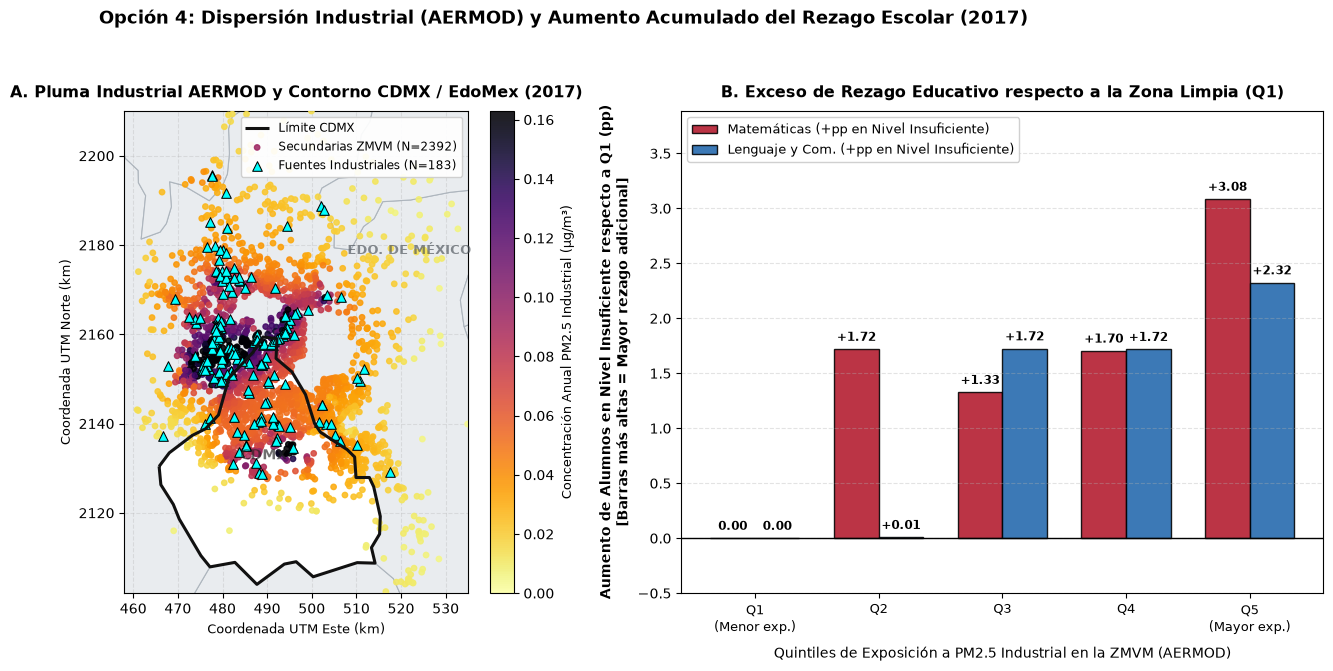

In [16]:
# --- OPCIÓN 4: BARRAS DE EXCESO DE REZAGO RESPECTO AL QUINTIL MÁS LIMPIO (Q1 = 0) ---
q_op4 = df_zmvm.groupby("quintil_pm", observed=False).agg(
    mat_brecha=("mat_brecha_rezago_n1", "mean"),
    lyc_brecha=("lyc_brecha_rezago_n1", "mean"),
).reset_index()

# Calcular el exceso de alumnos en Nivel I tomando Q1 como referencia (Q1 = 0)
q_op4["mat_exceso_q1"] = q_op4["mat_brecha"] - q_op4.loc[0, "mat_brecha"]
q_op4["lyc_exceso_q1"] = q_op4["lyc_brecha"] - q_op4.loc[0, "lyc_brecha"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_idx = np.arange(len(q_op4))
width = 0.36
b1 = ax2.bar(x_idx - width/2, q_op4["mat_exceso_q1"], width, color="#b2182b", alpha=0.88, edgecolor="black", label="Matemáticas (+pp en Nivel Insuficiente)")
b2 = ax2.bar(x_idx + width/2, q_op4["lyc_exceso_q1"], width, color="#2166ac", alpha=0.88, edgecolor="black", label="Lenguaje y Com. (+pp en Nivel Insuficiente)")

# Etiquetas de valor encima de cada barra
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax2.annotate(f"+{h:.2f}" if h > 0 else f"{h:.2f}",
                 xy=(bar.get_x() + bar.get_width() / 2, max(h, 0)),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax2.axhline(0, color="black", linewidth=1)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_op4["quintil_pm"], fontsize=9.5)
ax2.set_ylim(-0.5, max(q_op4["mat_exceso_q1"].max(), q_op4["lyc_exceso_q1"].max()) + 0.8)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial en la ZMVM (AERMOD)", fontsize=10, labelpad=8)
ax2.set_ylabel("Aumento de Alumnos en Nivel Insuficiente respecto a Q1 (pp)\n[Barras más altas = Mayor rezago adicional]", fontsize=10, fontweight="bold")
ax2.set_title("B. Exceso de Rezago Educativo respecto a la Zona Limpia (Q1)", fontsize=11.5, fontweight="bold", pad=10)
ax2.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.92, fontsize=9)
ax2.grid(True, axis="y", linestyle="--", alpha=0.35)

plt.suptitle("Opción 4: Dispersión Industrial (AERMOD) y Aumento Acumulado del Rezago Escolar (2017)", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_opcion4_barras_exceso_rezago.png", dpi=300)
plt.show()


### Después de argumentar con gemini

In [17]:
import os, urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Filtro del Grupo Grande Homogéneo en la ZMVM (X_UTM >= 460 km):
#    - Secundarias Públicas (Generales y Técnicas; excluye Privadas/Particulares y Telesecundarias rurales)
#    - Turno estrictamente MATUTINO
#    - Entorno Urbano (Marginación Muy Baja o Baja / sin alta marginación rural)
df_plt_zmvm = df_plt[df_plt["X_UTM"] >= 460000].copy()

cond_zmvm = df_m["X_UTM"] >= 460000
cond_publica = ~df_m["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR|TELE", na=False)
cond_matutino = df_m["turno"].astype(str).str.upper().str.strip() == "MATUTINO"
cond_urbana = ~df_m["marginacion"].astype(str).str.upper().str.contains("ALTA|MUY ALTA", na=False)

df_urb = df_m[cond_zmvm & cond_publica & cond_matutino & cond_urbana].dropna(
    subset=["PM25_CONC", "mat_pct_n1", "lyc_pct_n1", "mat_parecidas_n1", "lyc_parecidas_n1"]
).copy()

print(f"Total secundarias públicas matutinas urbanas en la ZMVM: {len(df_urb)}")
print("Distribución por tipo de escuela:\n", df_urb["tipo_escuela"].value_counts())

# 2. Métricas para Opción 1 (Ventaja relativa centrada en el promedio de la muestra ZMVM para que la media sea = 0)
mat_ventaja_cruda = df_urb["mat_parecidas_n1"] - df_urb["mat_pct_n1"]
lyc_ventaja_cruda = df_urb["lyc_parecidas_n1"] - df_urb["lyc_pct_n1"]

df_urb["mat_ventaja_zmvm"] = mat_ventaja_cruda - mat_ventaja_cruda.mean()
df_urb["lyc_ventaja_zmvm"] = lyc_ventaja_cruda - lyc_ventaja_cruda.mean()

# 3. Métricas para Opción 2 (Índice de Desempeño Global PURO en escala 0 a 100, SIN restar parecidas)
df_urb["mat_idx_global"] = ((1*df_urb["mat_pct_n1"] + 2*df_urb["mat_pct_n2"] + 3*df_urb["mat_pct_n3"] + 4*df_urb["mat_pct_n4"]) / 3.0) - (100.0 / 3.0)
df_urb["lyc_idx_global"] = ((1*df_urb["lyc_pct_n1"] + 2*df_urb["lyc_pct_n2"] + 3*df_urb["lyc_pct_n3"] + 4*df_urb["lyc_pct_n4"]) / 3.0) - (100.0 / 3.0)

# 4. Quintiles y Deciles dentro de este grupo homogéneo
df_urb["quintil_pm"] = pd.qcut(df_urb["PM25_CONC"], q=5, labels=["Q1\n(Menor exp.)", "Q2", "Q3", "Q4", "Q5\n(Mayor exp.)"])
df_urb["decil_pm"] = pd.qcut(df_urb["PM25_CONC"], q=10, labels=[f"D{i}" for i in range(1, 11)])

# 5. Cargar mapa con el contorno de CDMX remarcado
GEOJSON_STATES = f"{BASE}/02-data/processed/aermap_out/mexico_estados.geojson"
GEOJSON_MUN = f"{BASE}/02-data/processed/aermap_out/zmvm_municipios_inegi.geojson"

if not os.path.exists(GEOJSON_STATES):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/angelnmara/geojson/master/mexicoHigh.json", GEOJSON_STATES)

gdf_st = gpd.read_file(GEOJSON_STATES).to_crs("EPSG:32614")
gdf_st["geometry"] = gdf_st["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))
gdf_cdmx = gdf_st[gdf_st.geometry.centroid.x.between(470, 505) & gdf_st.geometry.centroid.y.between(2120, 2165)].copy()

gdf_mun = None
if os.path.exists(GEOJSON_MUN):
    gdf_mun = gpd.read_file(GEOJSON_MUN).to_crs("EPSG:32614")
    gdf_mun["geometry"] = gdf_mun["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))

def dibujar_mapa_zmvm(ax):
    ax.set_facecolor("#f2f4f7")
    gdf_st.plot(ax=ax, facecolor="#e9ecef", edgecolor="#adb5bd", linewidth=0.8, zorder=1)
    if gdf_mun is not None:
        gdf_mun.plot(ax=ax, facecolor="none", edgecolor="#ced4da", linewidth=0.45, zorder=2)
    if len(gdf_cdmx) > 0:
        gdf_cdmx.plot(ax=ax, facecolor="#ffffff", edgecolor="none", zorder=2)
        gdf_cdmx.boundary.plot(ax=ax, edgecolor="#111111", linewidth=2.2, zorder=5, label="Límite CDMX")

    vmax = np.percentile(df_urb["PM25_CONC"], 96)
    sc = ax.scatter(
        df_urb["X_UTM"] / 1000.0, df_urb["Y_UTM"] / 1000.0,
        c=df_urb["PM25_CONC"], cmap="inferno_r", s=16, alpha=0.88,
        vmin=0, vmax=vmax, zorder=3, label=f"Públicas Matutinas Urbanas (N={len(df_urb)})"
    )
    ax.scatter(
        df_src_active["X_UTM"] / 1000.0, df_src_active["Y_UTM"] / 1000.0,
        marker="^", c="cyan", edgecolors="black", s=48, linewidths=0.75,
        zorder=4, label=f"Fuentes Industriales (N={len(df_src_active)})"
    )
    ax.text(484, 2132, "CDMX", fontsize=10, fontweight="bold", color="#222222", alpha=0.65, zorder=6)
    ax.text(508, 2178, "EDO. DE MÉXICO", fontsize=9.5, fontweight="bold", color="#495057", alpha=0.65, zorder=6)

    ax.set_xlim(458, 535)
    ax.set_ylim(2102, 2210)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cbar.set_label("Concentración Anual PM2.5 Industrial (μg/m³)", fontsize=9.5)
    ax.set_title("A. Pluma Industrial AERMOD en Secundarias Públicas Matutinas (2017)", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Coordenada UTM Este (km)", fontsize=9.5)
    ax.set_ylabel("Coordenada UTM Norte (km)", fontsize=9.5)
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.3)
    ax.grid(True, linestyle="--", alpha=0.3, zorder=0)


Total secundarias públicas matutinas urbanas en la ZMVM: 539
Distribución por tipo de escuela:
 tipo_escuela
General Pública    350
Técnica Pública    189
Name: count, dtype: int64


      quintil_pm  n_esc  pm_mean  mat_mean  lyc_mean
Q1\n(Menor exp.)    108 0.029438 -2.352424 -3.067306
              Q2    108 0.050894  2.217946  2.094731
              Q3    108 0.062258  2.064243  2.248435
              Q4    107 0.082424  0.009786 -0.026392
Q5\n(Mayor exp.)    108 0.162229 -1.939461 -1.249713


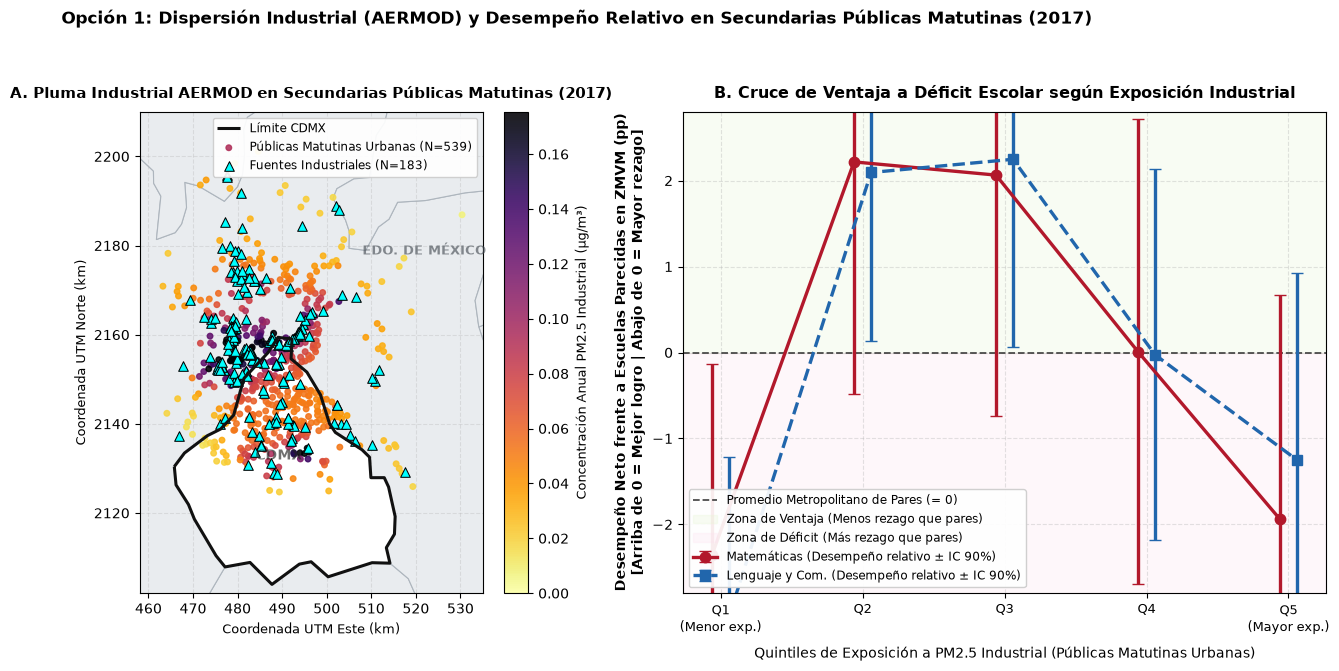

In [18]:
# --- OPCIÓN 1 (CORREGIDA): DESEMPEÑO NETO FRENTE A PARES CENTRADO EN 0 ---
q_op1 = df_urb.groupby("quintil_pm", observed=False).agg(
    n_esc=("cct", "count"),
    pm_mean=("PM25_CONC", "mean"),
    mat_mean=("mat_ventaja_zmvm", "mean"),
    mat_se=("mat_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
    lyc_mean=("lyc_ventaja_zmvm", "mean"),
    lyc_se=("lyc_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

print(q_op1[["quintil_pm", "n_esc", "pm_mean", "mat_mean", "lyc_mean"]].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_idx = np.arange(len(q_op1))
ax2.axhline(0, color="#222222", linestyle="--", linewidth=1.3, alpha=0.8, label="Promedio Metropolitano de Pares (= 0)")
ax2.axhspan(0, 3.5, color="#e6f5d0", alpha=0.25, label="Zona de Ventaja (Menos rezago que pares)")
ax2.axhspan(-3.5, 0, color="#fde0ef", alpha=0.25, label="Zona de Déficit (Más rezago que pares)")

ax2.errorbar(
    x_idx - 0.06, q_op1["mat_mean"], yerr=1.645 * q_op1["mat_se"],
    fmt="-o", color="#b2182b", linewidth=2.4, markersize=7.5, capsize=4,
    label="Matemáticas (Desempeño relativo ± IC 90%)"
)
ax2.errorbar(
    x_idx + 0.06, q_op1["lyc_mean"], yerr=1.645 * q_op1["lyc_se"],
    fmt="--s", color="#2166ac", linewidth=2.4, markersize=7.5, capsize=4,
    label="Lenguaje y Com. (Desempeño relativo ± IC 90%)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_op1["quintil_pm"], fontsize=9.5)
ax2.set_ylim(-2.8, 2.8)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial (Públicas Matutinas Urbanas)", fontsize=10, labelpad=8)
ax2.set_ylabel("Desempeño Neto frente a Escuelas Parecidas en ZMVM (pp)\n[Arriba de 0 = Mejor logro | Abajo de 0 = Mayor rezago]", fontsize=9.8, fontweight="bold")
ax2.set_title("B. Cruce de Ventaja a Déficit Escolar según Exposición Industrial", fontsize=11.2, fontweight="bold", pad=10)
ax2.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.5)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.suptitle("Opción 1: Dispersión Industrial (AERMOD) y Desempeño Relativo en Secundarias Públicas Matutinas (2017)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_opcion1_centrada_cero.png", dpi=300)
plt.show()


      quintil_pm  n_esc  pm_mean   mat_idx   lyc_idx
Q1\n(Menor exp.)    108 0.029438 28.494136 44.552469
              Q2    108 0.050894 30.675309 46.943827
              Q3    108 0.062258 30.530864 47.217593
              Q4    107 0.082424 30.446106 46.685358
Q5\n(Mayor exp.)    108 0.162229 28.436111 45.225309


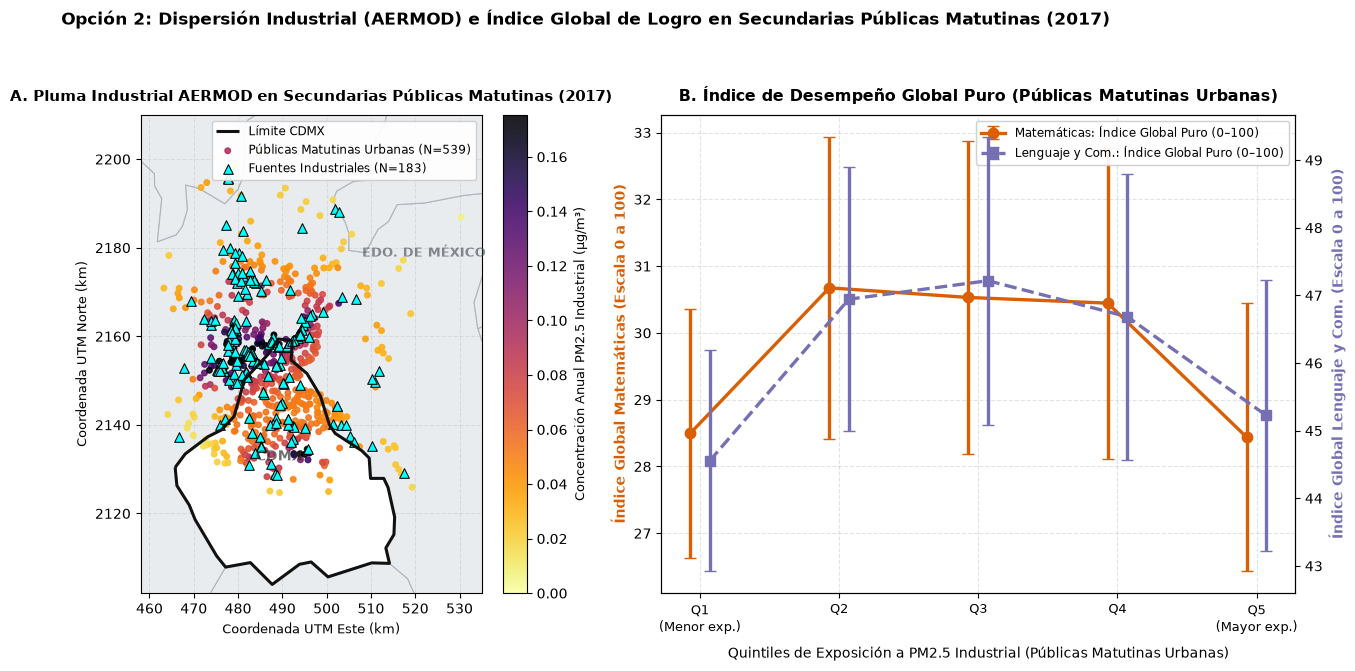

In [19]:
# --- OPCIÓN 2 (CORREGIDA): ÍNDICE DE DESEMPEÑO GLOBAL PURO (SIN DIFERENCIAS) ---
q_op2 = df_urb.groupby("quintil_pm", observed=False).agg(
    n_esc=("cct", "count"),
    pm_mean=("PM25_CONC", "mean"),
    mat_idx=("mat_idx_global", "mean"),
    mat_se=("mat_idx_global", lambda x: x.std() / np.sqrt(len(x))),
    lyc_idx=("lyc_idx_global", "mean"),
    lyc_se=("lyc_idx_global", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

print(q_op2[["quintil_pm", "n_esc", "pm_mean", "mat_idx", "lyc_idx"]].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_idx = np.arange(len(q_op2))
ax2.errorbar(
    x_idx - 0.07, q_op2["mat_idx"], yerr=1.645 * q_op2["mat_se"],
    fmt="-o", color="#d95f02", linewidth=2.4, markersize=7.5, capsize=4,
    label="Matemáticas: Índice Global Puro (0–100)"
)
ax2_twin = ax2.twinx()
ax2_twin.errorbar(
    x_idx + 0.07, q_op2["lyc_idx"], yerr=1.645 * q_op2["lyc_se"],
    fmt="--s", color="#7570b3", linewidth=2.4, markersize=7.5, capsize=4,
    label="Lenguaje y Com.: Índice Global Puro (0–100)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_op2["quintil_pm"], fontsize=9.5)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial (Públicas Matutinas Urbanas)", fontsize=10, labelpad=8)
ax2.set_ylabel("Índice Global Matemáticas (Escala 0 a 100)", color="#d95f02", fontsize=10, fontweight="bold")
ax2_twin.set_ylabel("Índice Global Lenguaje y Com. (Escala 0 a 100)", color="#7570b3", fontsize=10, fontweight="bold")
ax2.set_title("B. Índice de Desempeño Global Puro (Públicas Matutinas Urbanas)", fontsize=11.2, fontweight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.35)

l1, lab1 = ax2.get_legend_handles_labels()
l2, lab2 = ax2_twin.get_legend_handles_labels()
ax2.legend(l1 + l2, lab1 + lab2, loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.8)

plt.suptitle("Opción 2: Dispersión Industrial (AERMOD) e Índice Global de Logro en Secundarias Públicas Matutinas (2017)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_opcion2_indice_global_puro.png", dpi=300)
plt.show()


### Visualizaciones corregidas

=== PASO 1: SECUNDARIAS PÚBLICAS ZMVM (N=2,384) - VENTAJA CENTRADA EN 0 ===
      quintil_pm  n_esc  pm_mean  mat_mean  lyc_mean
Q1\n(Menor exp.)    477 0.018494  1.565420  1.154029
              Q2    477 0.036159 -0.153867  1.146063
              Q3    477 0.051107  0.238586 -0.569660
              Q4    478 0.071015 -0.137587 -0.564159
Q5\n(Mayor exp.)    475 0.138516 -1.518631 -1.169996


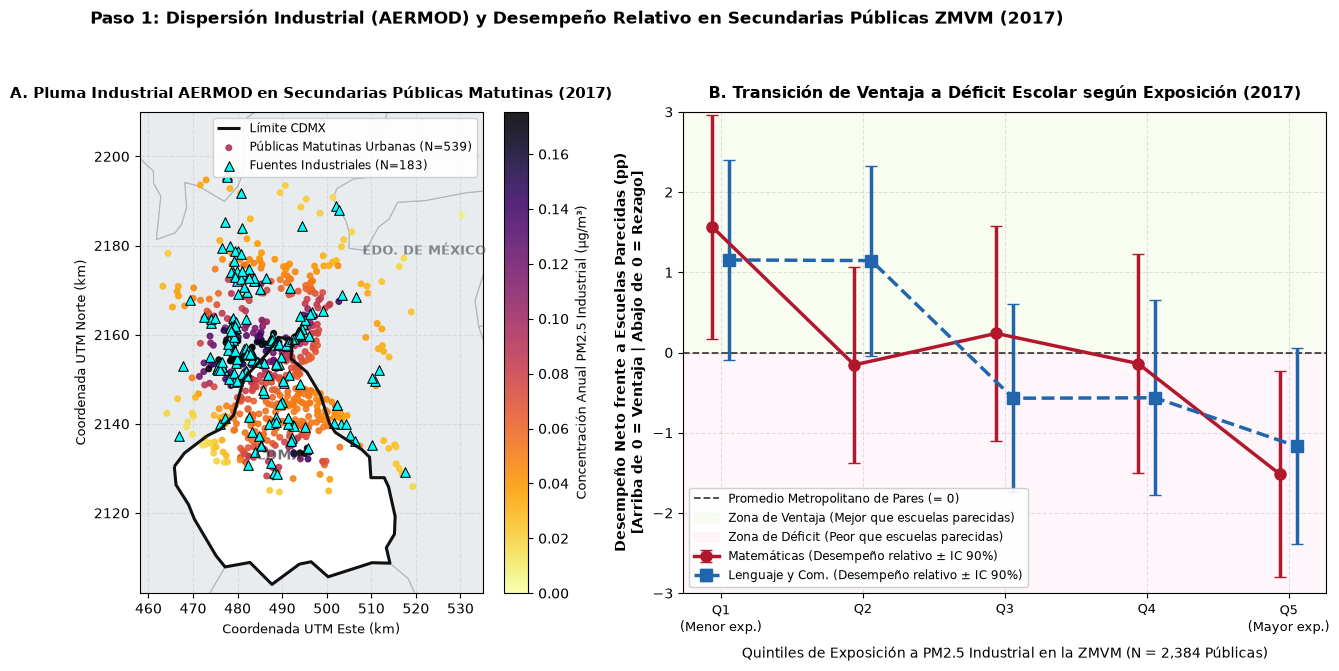

In [20]:
# === PASO 1: UNIVERSO COMPLETO DE SECUNDARIAS PÚBLICAS ZMVM (N=2,384) - OPCIÓN 1 CENTRADA EN 0 ===
df_pub = df_m[
    (df_m["X_UTM"] >= 460000) &
    (~df_m["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False))
].dropna(subset=["PM25_CONC", "mat_pct_n1", "lyc_pct_n1", "mat_parecidas_n1", "lyc_parecidas_n1"]).copy()

# Ventaja bruta (Parecidas - Escuela: valores mayores = menos reprobados que sus pares)
df_pub["mat_ventaja"] = df_pub["mat_parecidas_n1"] - df_pub["mat_pct_n1"]
df_pub["lyc_ventaja"] = df_pub["lyc_parecidas_n1"] - df_pub["lyc_pct_n1"]

# Centrar respecto al promedio metropolitano para que la línea 0 divida exactamente ventaja (+) vs déficit (-)
df_pub["mat_ventaja_zmvm"] = df_pub["mat_ventaja"] - df_pub["mat_ventaja"].mean()
df_pub["lyc_ventaja_zmvm"] = df_pub["lyc_ventaja"] - df_pub["lyc_ventaja"].mean()

# Índice de Desempeño Global (0 a 100) y su versión ajustada por estrato (comparacion_parecidas)
df_pub["mat_idx_global"] = ((1*df_pub["mat_pct_n1"] + 2*df_pub["mat_pct_n2"] + 3*df_pub["mat_pct_n3"] + 4*df_pub["mat_pct_n4"]) / 3.0) - (100.0 / 3.0)
df_pub["lyc_idx_global"] = ((1*df_pub["lyc_pct_n1"] + 2*df_pub["lyc_pct_n2"] + 3*df_pub["lyc_pct_n3"] + 4*df_pub["lyc_pct_n4"]) / 3.0) - (100.0 / 3.0)

df_pub["quintil_pm"] = pd.qcut(df_pub["PM25_CONC"], q=5, labels=["Q1\n(Menor exp.)", "Q2", "Q3", "Q4", "Q5\n(Mayor exp.)"])
df_pub["decil_pm"] = pd.qcut(df_pub["PM25_CONC"], q=10, labels=[f"D{i}" for i in range(1, 11)])

q_step1 = df_pub.groupby("quintil_pm", observed=False).agg(
    n_esc=("cct", "count"),
    pm_mean=("PM25_CONC", "mean"),
    mat_mean=("mat_ventaja_zmvm", "mean"),
    mat_se=("mat_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
    lyc_mean=("lyc_ventaja_zmvm", "mean"),
    lyc_se=("lyc_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

print("=== PASO 1: SECUNDARIAS PÚBLICAS ZMVM (N=2,384) - VENTAJA CENTRADA EN 0 ===")
print(q_step1[["quintil_pm", "n_esc", "pm_mean", "mat_mean", "lyc_mean"]].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_idx = np.arange(len(q_step1))
ax2.axhline(0, color="#222222", linestyle="--", linewidth=1.3, alpha=0.85, label="Promedio Metropolitano de Pares (= 0)")
ax2.axhspan(0, 3.2, color="#e6f5d0", alpha=0.28, label="Zona de Ventaja (Mejor que escuelas parecidas)")
ax2.axhspan(-3.2, 0, color="#fde0ef", alpha=0.28, label="Zona de Déficit (Peor que escuelas parecidas)")

ax2.errorbar(
    x_idx - 0.06, q_step1["mat_mean"], yerr=1.645 * q_step1["mat_se"],
    fmt="-o", color="#b2182b", linewidth=2.5, markersize=8, capsize=4,
    label="Matemáticas (Desempeño relativo ± IC 90%)"
)
ax2.errorbar(
    x_idx + 0.06, q_step1["lyc_mean"], yerr=1.645 * q_step1["lyc_se"],
    fmt="--s", color="#2166ac", linewidth=2.5, markersize=8, capsize=4,
    label="Lenguaje y Com. (Desempeño relativo ± IC 90%)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_step1["quintil_pm"], fontsize=9.5)
ax2.set_ylim(-3.0, 3.0)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial en la ZMVM (N = 2,384 Públicas)", fontsize=10, labelpad=8)
ax2.set_ylabel("Desempeño Neto frente a Escuelas Parecidas (pp)\n[Arriba de 0 = Ventaja | Abajo de 0 = Rezago]", fontsize=10, fontweight="bold")
ax2.set_title("B. Transición de Ventaja a Déficit Escolar según Exposición (2017)", fontsize=11.5, fontweight="bold", pad=10)
ax2.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.8)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.suptitle("Paso 1: Dispersión Industrial (AERMOD) y Desempeño Relativo en Secundarias Públicas ZMVM (2017)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_paso1_ventaja_zmvm_2384.png", dpi=300)
plt.show()


=== PASO 2: TABLA POR DECILES DE EXPOSICIÓN (D1 A D10) ===
decil_pm  n_esc  pm_mean  mat_mean  lyc_mean
      D1    239 0.013219  3.012622  1.599858
      D2    238 0.023791  0.112138  0.706328
      D3    238 0.032094  0.163399  2.223554
      D4    239 0.040208 -0.469805  0.073080
      D5    238 0.047737 -1.459290 -2.230647
      D6    239 0.054464  1.929358  1.084377
      D7    240 0.063940  1.097685  1.159692
      D8    238 0.078149 -1.383240 -2.302496
      D9    236 0.101170 -2.477824 -1.534382
     D10    239 0.175394 -0.571479 -0.810184


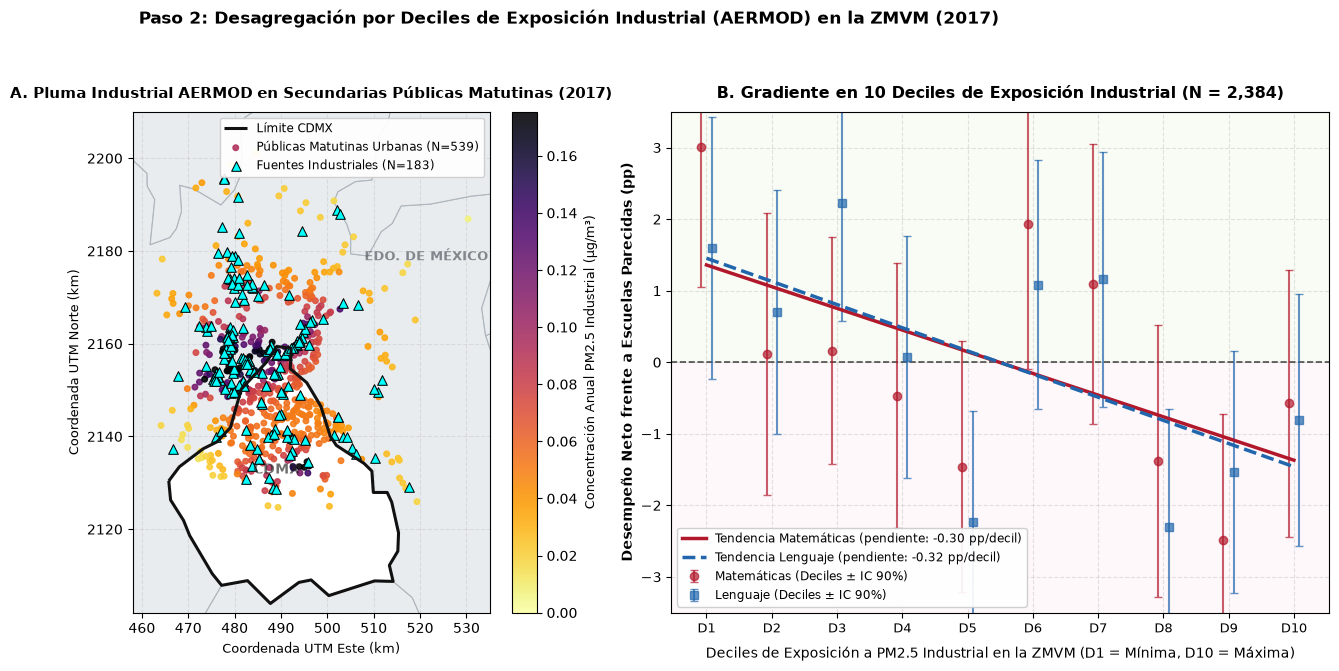

In [21]:
# === PASO 2: ANÁLISIS EN 10 DECILES (D1 A D10) SOBRE EL UNIVERSO PÚBLICO (N=2,384) ===
d_step2 = df_pub.groupby("decil_pm", observed=False).agg(
    n_esc=("cct", "count"),
    pm_mean=("PM25_CONC", "mean"),
    mat_mean=("mat_ventaja_zmvm", "mean"),
    mat_se=("mat_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
    lyc_mean=("lyc_ventaja_zmvm", "mean"),
    lyc_se=("lyc_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

print("=== PASO 2: TABLA POR DECILES DE EXPOSICIÓN (D1 A D10) ===")
print(d_step2[["decil_pm", "n_esc", "pm_mean", "mat_mean", "lyc_mean"]].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

x_d = np.arange(1, 11)
ax2.axhline(0, color="#222222", linestyle="--", linewidth=1.2, alpha=0.8)
ax2.axhspan(0, 3.8, color="#e6f5d0", alpha=0.22)
ax2.axhspan(-3.8, 0, color="#fde0ef", alpha=0.22)

ax2.errorbar(x_d - 0.08, d_step2["mat_mean"], yerr=1.645 * d_step2["mat_se"], fmt="o", color="#b2182b", alpha=0.7, capsize=3, label="Matemáticas (Deciles ± IC 90%)")
ax2.errorbar(x_d + 0.08, d_step2["lyc_mean"], yerr=1.645 * d_step2["lyc_se"], fmt="s", color="#2166ac", alpha=0.7, capsize=3, label="Lenguaje (Deciles ± IC 90%)")

# Tendencia lineal/polinomial suave sobre los 10 deciles
x_smooth = np.linspace(1, 10, 100)
p_mat = np.poly1d(np.polyfit(x_d, d_step2["mat_mean"], deg=1))
p_lyc = np.poly1d(np.polyfit(x_d, d_step2["lyc_mean"], deg=1))
ax2.plot(x_smooth, p_mat(x_smooth), "-", color="#b2182b", linewidth=2.5, label=f"Tendencia Matemáticas (pendiente: {p_mat[1]:.2f} pp/decil)")
ax2.plot(x_smooth, p_lyc(x_smooth), "--", color="#2166ac", linewidth=2.5, label=f"Tendencia Lenguaje (pendiente: {p_lyc[1]:.2f} pp/decil)")

ax2.set_xticks(x_d)
ax2.set_xticklabels(d_step2["decil_pm"], fontsize=9.5)
ax2.set_ylim(-3.5, 3.5)
ax2.set_xlabel("Deciles de Exposición a PM2.5 Industrial en la ZMVM (D1 = Mínima, D10 = Máxima)", fontsize=10, labelpad=8)
ax2.set_ylabel("Desempeño Neto frente a Escuelas Parecidas (pp)", fontsize=10, fontweight="bold")
ax2.set_title("B. Gradiente en 10 Deciles de Exposición Industrial (N = 2,384)", fontsize=11.5, fontweight="bold", pad=10)
ax2.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.5)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.suptitle("Paso 2: Desagregación por Deciles de Exposición Industrial (AERMOD) en la ZMVM (2017)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_paso2_deciles_2384.png", dpi=300)
plt.show()


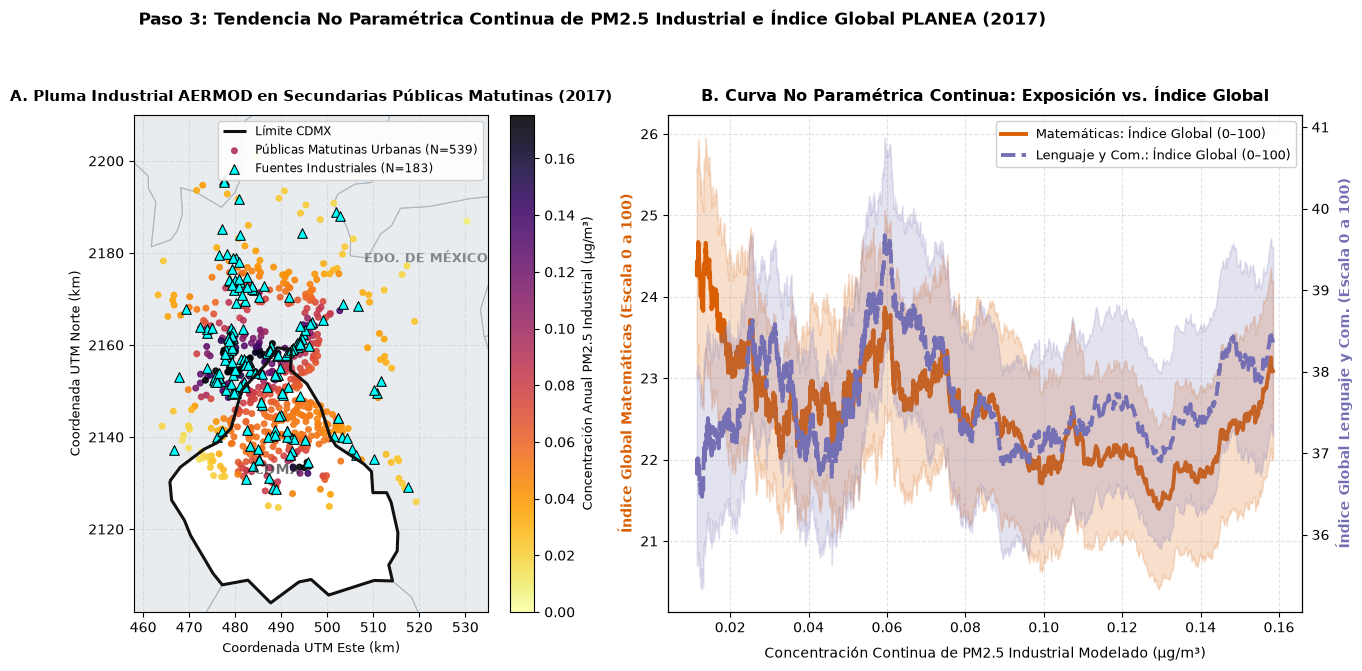

In [22]:
# === PASO 3: CURVA CONTINUA NO PARAMÉTRICA (SIN QUINTILES ARTIFICIALES) ===
# Recortar el 1% extremo superior de PM2.5 solo para visualización continua limpia en el eje X
p99 = np.percentile(df_pub["PM25_CONC"], 99)
df_cont = df_pub[df_pub["PM25_CONC"] <= p99].sort_values("PM25_CONC").copy()

# Índice Global ajustado dentro del grupo de comparación de la SEP (mantiene la escala de 0 a 100 puntos)
df_cont["mat_idx_adj"] = df_cont["mat_idx_global"] - df_cont.groupby("comparacion_parecidas")["mat_idx_global"].transform("mean") + df_cont["mat_idx_global"].mean()
df_cont["lyc_idx_adj"] = df_cont["lyc_idx_global"] - df_cont.groupby("comparacion_parecidas")["lyc_idx_global"].transform("mean") + df_cont["lyc_idx_global"].mean()

# Calcular curva suavizada por ventana móvil (Rolling Lowess-style) de 350 escuelas
win = 350
df_cont["pm_roll"] = df_cont["PM25_CONC"].rolling(win, center=True, min_periods=100).mean()
df_cont["mat_roll"] = df_cont["mat_idx_adj"].rolling(win, center=True, min_periods=100).mean()
df_cont["mat_roll_se"] = df_cont["mat_idx_adj"].rolling(win, center=True, min_periods=100).std() / np.sqrt(win)

df_cont["lyc_roll"] = df_cont["lyc_idx_adj"].rolling(win, center=True, min_periods=100).mean()
df_cont["lyc_roll_se"] = df_cont["lyc_idx_adj"].rolling(win, center=True, min_periods=100).std() / np.sqrt(win)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm(ax1)

# Graficar curva continua suavizada con banda de intervalo de confianza al 90%
ax2.plot(df_cont["pm_roll"], df_cont["mat_roll"], "-", color="#d95f02", linewidth=2.8, label="Matemáticas: Índice Global (0–100)")
ax2.fill_between(
    df_cont["pm_roll"],
    df_cont["mat_roll"] - 1.645 * df_cont["mat_roll_se"],
    df_cont["mat_roll"] + 1.645 * df_cont["mat_roll_se"],
    color="#d95f02", alpha=0.2
)

ax2_twin = ax2.twinx()
ax2_twin.plot(df_cont["pm_roll"], df_cont["lyc_roll"], "--", color="#7570b3", linewidth=2.8, label="Lenguaje y Com.: Índice Global (0–100)")
ax2_twin.fill_between(
    df_cont["pm_roll"],
    df_cont["lyc_roll"] - 1.645 * df_cont["lyc_roll_se"],
    df_cont["lyc_roll"] + 1.645 * df_cont["lyc_roll_se"],
    color="#7570b3", alpha=0.2
)

ax2.set_xlabel("Concentración Continua de PM2.5 Industrial Modelado (μg/m³)", fontsize=10, labelpad=8)
ax2.set_ylabel("Índice Global Matemáticas (Escala 0 a 100)", color="#d95f02", fontsize=10, fontweight="bold")
ax2_twin.set_ylabel("Índice Global Lenguaje y Com. (Escala 0 a 100)", color="#7570b3", fontsize=10, fontweight="bold")
ax2.set_title("B. Curva No Paramétrica Continua: Exposición vs. Índice Global", fontsize=11.5, fontweight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.35)

l1, lab1 = ax2.get_legend_handles_labels()
l2, lab2 = ax2_twin.get_legend_handles_labels()
ax2.legend(l1 + l2, lab1 + lab2, loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=9)

plt.suptitle("Paso 3: Tendencia No Paramétrica Continua de PM2.5 Industrial e Índice Global PLANEA (2017)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_paso3_curva_continua_lowess.png", dpi=300)
plt.show()


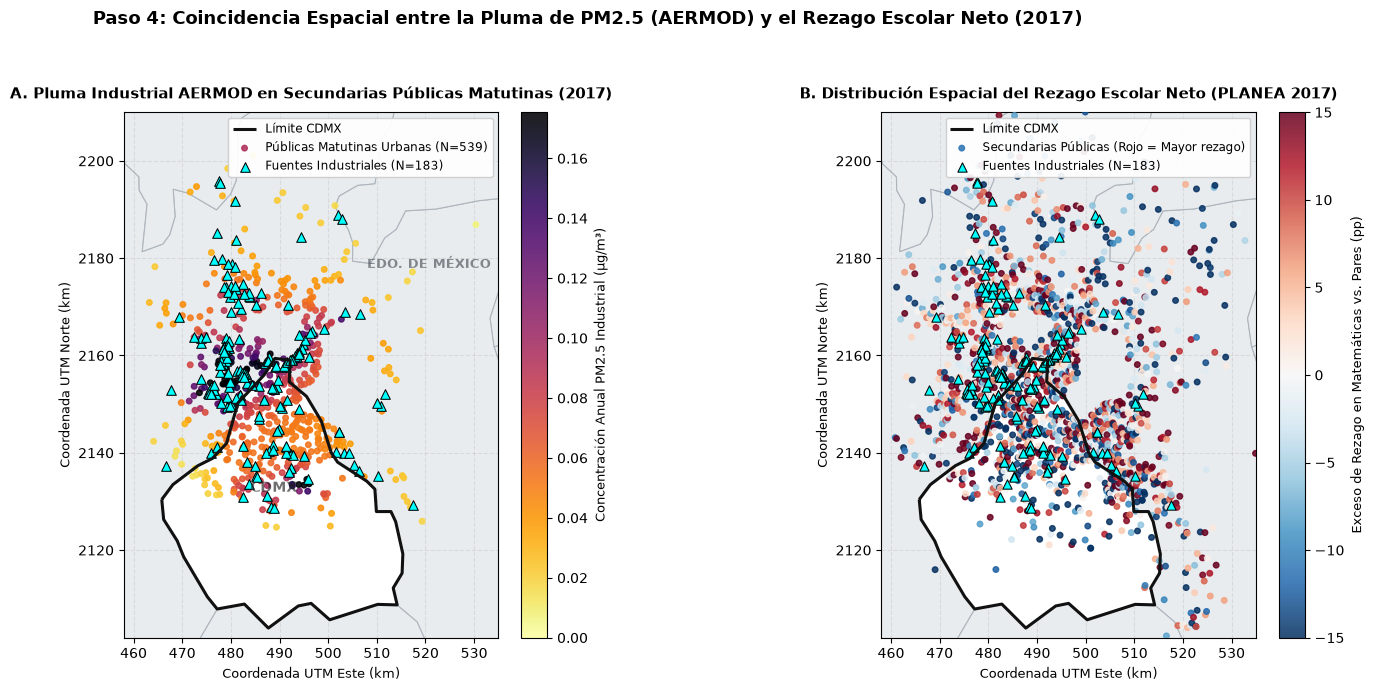

In [23]:
# === PASO 4: MAPA COMPARATIVO DE PLUMA INDUSTRIAL VS. HOTSPOTS DE REZAGO ESCOLAR ===
# Promediar por inmueble escolar único (X_UTM, Y_UTM) para evitar superposición de turnos
df_esc_map = df_pub.groupby(["X_UTM", "Y_UTM"], as_index=False).agg(
    PM25_CONC=("PM25_CONC", "mean"),
    deficit_promedio=("mat_brecha_rezago_n1", lambda s: (s.mean() - df_pub["mat_brecha_rezago_n1"].mean()))
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.0))

# Panel A: Pluma Industrial AERMOD
dibujar_mapa_zmvm(ax1)

# Panel B: Mapa de Hotspots de Rezago Escolar (Residuales contra Escuelas Parecidas)
ax2.set_facecolor("#f2f4f7")
gdf_st.plot(ax=ax2, facecolor="#e9ecef", edgecolor="#adb5bd", linewidth=0.8, zorder=1)
if gdf_mun is not None:
    gdf_mun.plot(ax=ax2, facecolor="none", edgecolor="#ced4da", linewidth=0.45, zorder=2)
if len(gdf_cdmx) > 0:
    gdf_cdmx.plot(ax=ax2, facecolor="#ffffff", edgecolor="none", zorder=2)
    gdf_cdmx.boundary.plot(ax=ax2, edgecolor="#111111", linewidth=2.2, zorder=5, label="Límite CDMX")

sc2 = ax2.scatter(
    df_esc_map["X_UTM"] / 1000.0, df_esc_map["Y_UTM"] / 1000.0,
    c=df_esc_map["deficit_promedio"], cmap="RdBu_r", s=16, alpha=0.85,
    vmin=-15, vmax=15, zorder=3, label="Secundarias Públicas (Rojo = Mayor rezago)"
)
ax2.scatter(
    df_src_active["X_UTM"] / 1000.0, df_src_active["Y_UTM"] / 1000.0,
    marker="^", c="cyan", edgecolors="black", s=45, linewidths=0.75,
    zorder=4, label=f"Fuentes Industriales (N={len(df_src_active)})"
)

ax2.set_xlim(458, 535)
ax2.set_ylim(2102, 2210)
cbar2 = plt.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.03)
cbar2.set_label("Exceso de Rezago en Matemáticas vs. Pares (pp)", fontsize=9.5)
ax2.set_title("B. Distribución Espacial del Rezago Escolar Neto (PLANEA 2017)", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("Coordenada UTM Este (km)", fontsize=9.5)
ax2.set_ylabel("Coordenada UTM Norte (km)", fontsize=9.5)
ax2.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.3)
ax2.grid(True, linestyle="--", alpha=0.3, zorder=0)

plt.suptitle("Paso 4: Coincidencia Espacial entre la Pluma de PM2.5 (AERMOD) y el Rezago Escolar Neto (2017)", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_paso4_mapa_residuos.png", dpi=300)
plt.show()


### la buena

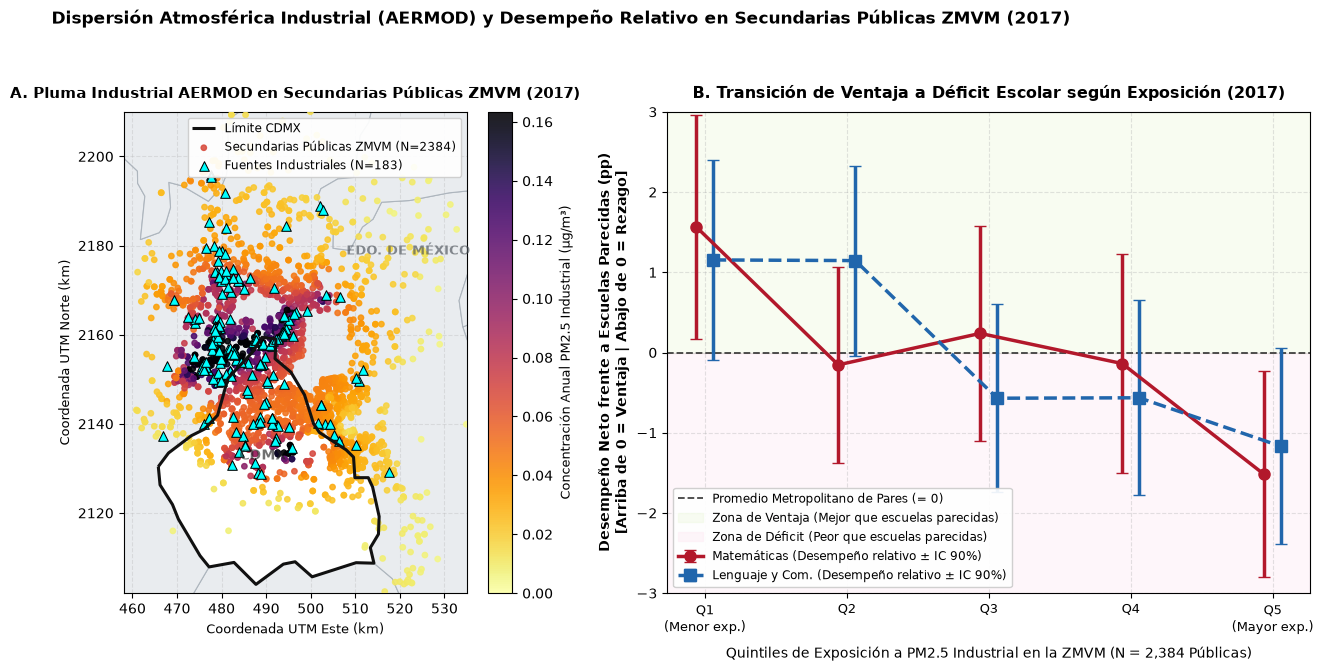

In [24]:
# === FIGURA 1 DEFINITIVA: COHERENCIA TOTAL EN EL UNIVERSO DE SECUNDARIAS PÚBLICAS ZMVM (N=2,384) ===
df_pub = df_m[
    (df_m["X_UTM"] >= 460000) &
    (~df_m["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False))
].dropna(subset=["PM25_CONC", "mat_pct_n1", "lyc_pct_n1", "mat_parecidas_n1", "lyc_parecidas_n1"]).copy()

# Ventaja bruta (Parecidas - Escuela) y centrada respecto al promedio metropolitano (= 0)
df_pub["mat_ventaja"] = df_pub["mat_parecidas_n1"] - df_pub["mat_pct_n1"]
df_pub["lyc_ventaja"] = df_pub["lyc_parecidas_n1"] - df_pub["lyc_pct_n1"]
df_pub["mat_ventaja_zmvm"] = df_pub["mat_ventaja"] - df_pub["mat_ventaja"].mean()
df_pub["lyc_ventaja_zmvm"] = df_pub["lyc_ventaja"] - df_pub["lyc_ventaja"].mean()

df_pub["quintil_pm"] = pd.qcut(df_pub["PM25_CONC"], q=5, labels=["Q1\n(Menor exp.)", "Q2", "Q3", "Q4", "Q5\n(Mayor exp.)"])

q_step1 = df_pub.groupby("quintil_pm", observed=False).agg(
    n_esc=("cct", "count"),
    pm_mean=("PM25_CONC", "mean"),
    mat_mean=("mat_ventaja_zmvm", "mean"),
    mat_se=("mat_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
    lyc_mean=("lyc_ventaja_zmvm", "mean"),
    lyc_se=("lyc_ventaja_zmvm", lambda x: x.std() / np.sqrt(len(x))),
).reset_index()

def dibujar_mapa_zmvm_completo(ax, df_schools):
    ax.set_facecolor("#f2f4f7")
    gdf_st.plot(ax=ax, facecolor="#e9ecef", edgecolor="#adb5bd", linewidth=0.8, zorder=1)
    if gdf_mun is not None:
        gdf_mun.plot(ax=ax, facecolor="none", edgecolor="#ced4da", linewidth=0.45, zorder=2)
    if len(gdf_cdmx) > 0:
        gdf_cdmx.plot(ax=ax, facecolor="#ffffff", edgecolor="none", zorder=2)
        gdf_cdmx.boundary.plot(ax=ax, edgecolor="#111111", linewidth=2.2, zorder=5, label="Límite CDMX")

    vmax = np.percentile(df_schools["PM25_CONC"], 96)
    sc = ax.scatter(
        df_schools["X_UTM"] / 1000.0, df_schools["Y_UTM"] / 1000.0,
        c=df_schools["PM25_CONC"], cmap="inferno_r", s=15, alpha=0.88,
        vmin=0, vmax=vmax, zorder=3, label=f"Secundarias Públicas ZMVM (N={len(df_schools)})"
    )
    ax.scatter(
        df_src_active["X_UTM"] / 1000.0, df_src_active["Y_UTM"] / 1000.0,
        marker="^", c="cyan", edgecolors="black", s=48, linewidths=0.75,
        zorder=4, label=f"Fuentes Industriales (N={len(df_src_active)})"
    )
    ax.text(484, 2132, "CDMX", fontsize=10, fontweight="bold", color="#222222", alpha=0.65, zorder=6)
    ax.text(508, 2178, "EDO. DE MÉXICO", fontsize=9.5, fontweight="bold", color="#495057", alpha=0.65, zorder=6)

    ax.set_xlim(458, 535)
    ax.set_ylim(2102, 2210)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cbar.set_label("Concentración Anual PM2.5 Industrial (μg/m³)", fontsize=9.5)
    ax.set_title("A. Pluma Industrial AERMOD en Secundarias Públicas ZMVM (2017)", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Coordenada UTM Este (km)", fontsize=9.5)
    ax.set_ylabel("Coordenada UTM Norte (km)", fontsize=9.5)
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.3)
    ax.grid(True, linestyle="--", alpha=0.3, zorder=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.12, 1]})
dibujar_mapa_zmvm_completo(ax1, df_pub)

x_idx = np.arange(len(q_step1))
ax2.axhline(0, color="#222222", linestyle="--", linewidth=1.3, alpha=0.85, label="Promedio Metropolitano de Pares (= 0)")
ax2.axhspan(0, 3.2, color="#e6f5d0", alpha=0.28, label="Zona de Ventaja (Mejor que escuelas parecidas)")
ax2.axhspan(-3.2, 0, color="#fde0ef", alpha=0.28, label="Zona de Déficit (Peor que escuelas parecidas)")

ax2.errorbar(
    x_idx - 0.06, q_step1["mat_mean"], yerr=1.645 * q_step1["mat_se"],
    fmt="-o", color="#b2182b", linewidth=2.5, markersize=8, capsize=4,
    label="Matemáticas (Desempeño relativo ± IC 90%)"
)
ax2.errorbar(
    x_idx + 0.06, q_step1["lyc_mean"], yerr=1.645 * q_step1["lyc_se"],
    fmt="--s", color="#2166ac", linewidth=2.5, markersize=8, capsize=4,
    label="Lenguaje y Com. (Desempeño relativo ± IC 90%)"
)

ax2.set_xticks(x_idx)
ax2.set_xticklabels(q_step1["quintil_pm"], fontsize=9.5)
ax2.set_ylim(-3.0, 3.0)
ax2.set_xlabel("Quintiles de Exposición a PM2.5 Industrial en la ZMVM (N = 2,384 Públicas)", fontsize=10, labelpad=8)
ax2.set_ylabel("Desempeño Neto frente a Escuelas Parecidas (pp)\n[Arriba de 0 = Ventaja | Abajo de 0 = Rezago]", fontsize=10, fontweight="bold")
ax2.set_title("B. Transición de Ventaja a Déficit Escolar según Exposición (2017)", fontsize=11.5, fontweight="bold", pad=10)
ax2.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.8)
ax2.grid(True, linestyle="--", alpha=0.35)

plt.suptitle("Dispersión Atmosférica Industrial (AERMOD) y Desempeño Relativo en Secundarias Públicas ZMVM (2017)", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(f"{BASE}/03-analysis/run_aermod/fig_paso1_ventaja_zmvm_2384.png", dpi=300)
plt.show()


* **Alcance metodológico:** Cruce espacial entre modelación de dispersión atmosférica industrial (**AERMOD**, meteorología horaria y factores de emisión **RETC**) y los resultados de logro educativo (**PLANEA 2017**) en $2,384$ secundarias públicas de la ZMVM.
* **Panel Izquierdo (Exposición a $\text{PM}_{2.5}$ industrial):**
* Muestra la concentración media anual estimada por plantel y las $183$ instalaciones industriales activas en 2017 (triángulos).
* Evidencia cómo los vientos dominantes de la cuenca transportan la pluma contaminante desde los corredores industriales del norte y oriente hacia el centro-sur de la CDMX.
* Muestra una variación de exposición de $7.49\text{x}$ entre el quintil más limpio ($Q_1 = 0.0185 \text{ }\mu\text{g/m}^3$) y el más expuesto ($Q_5 = 0.1385 \text{ }\mu\text{g/m}^3$).


* **Panel Derecho (Desempeño relativo vs. escuelas parecidas):**
* Utiliza la métrica de **"escuelas parecidas"** de la SEP (mismo tipo de servicio, entidad y grado de marginación) para controlar preliminarmente el sesgo socioeconómico sin requerir aún el modelo econométrico completo.
* El eje vertical mide la ventaja neta de cada escuela frente a seus pares (% de alumnos en Nivel I o Insuficiente en escuelas parecidas menos el porcentaje de la escuela expuesta), centrada en el promedio metropolitano ($0$).